In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 1 — Install
# ─────────────────────────────────────────────────────────────────────────────
!pip install qiskit qiskit-aer matplotlib numpy --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 80.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 74.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 3.9 MB/s eta 0:00:00


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 2 — Imports
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.quantum_info import DensityMatrix, partial_trace, state_fidelity, Statevector

print('All imports OK')

All imports OK


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 3 — Noise model
# ─────────────────────────────────────────────────────────────────────────────
def build_noise_model(p: float) -> NoiseModel:
    """Depolarizing noise model: rate p per qubit per gate."""
    nm   = NoiseModel()
    err1 = depolarizing_error(p, 1)
    err2 = depolarizing_error(p, 2)
    nm.add_all_qubit_quantum_error(
         err1, ['u1'] # ['u', 'u1', 'u2', 'u3', 'id', 'h', 'x', 'z', 'y']
     )
    nm.add_all_qubit_quantum_error(err2, ['cx'])
    print(nm)
    return nm


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 4 — Encoder / decoder helpers
# ─────────────────────────────────────────────────────────────────────────────
def css_encode(qc: QuantumCircuit, data: QuantumRegister) -> None:
    """CSS encoder: data[0] carries the logical qubit."""
    qc.cx(data[0], data[1])
    qc.cx(data[0], data[2])

def css_decode(qc: QuantumCircuit, data: QuantumRegister) -> None:
    """Inverse CSS encoder (CNOTs are self-inverse, reversed order)."""
    qc.cx(data[0], data[2])
    qc.cx(data[0], data[1])


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 5 — Syndrome tables
#
# IMPORTANT: The 3-qubit repetition code has stabilizer group generated by
#   {Z₀Z₁, Z₁Z₂, X₀X₁X₂}
#
# X₀X₁ and X₁X₂ are NOT stabilizers of this code — they anticommute with
# the logical Z̄ operator.  Only the full 3-qubit parity X₀X₁X₂ is in the
# stabilizer group.  This means Z errors cannot be located (all three Z-error
# positions are in the same syndrome coset); we can only detect that a Z error
# occurred and correct it by applying Z to qubit 0.
# ─────────────────────────────────────────────────────────────────────────────
X_SYNDROME = {
    # (s0=Z₀Z₁, s1=Z₁Z₂) → X correction
    (0, 0): None,
    (1, 0): ('X', 1),   # Z₀Z₁ fires, Z₁Z₂ silent → X on qubit 1
    (0, 1): ('X', 2),   # Z₀Z₁ silent, Z₁Z₂ fires → X on qubit 2
    (1, 1): ('X', 0),   # both fire                → X on qubit 0
}
# sz=X₀X₁X₂ → Z correction (detect any Z error; correct on qubit 0)
# sz=0: no Z error.  sz=1: Z error occurred → apply Z to qubit 0.

def decode_syndrome(syn_str: str):
    """
    Parse a 3-bit Qiskit counts string (LSB-first) into corrections.
    syn_str bit layout after reversal: [s0=Z₀Z₁, s1=Z₁Z₂, sz=X₀X₁X₂]
    Returns (x_corr, z_corr) where each is ('X'/'Z', qubit_index) or None.
    """
    bits = [int(b) for b in syn_str[::-1]]   # Qiskit LSB-first → reverse
    s0, s1, sz = bits[0], bits[1], bits[2]
    x_corr = X_SYNDROME.get((s0, s1))
    z_corr = ('Z', 0) if sz == 1 else None
    return x_corr, z_corr

# Quick verification
print('Syndrome decoding verification:')
print(f'  000 (no error)       → {decode_syndrome("000")}')
print(f'  010 (X on qubit 1)   → {decode_syndrome("010")}')
print(f'  110 (X on qubit 0)   → {decode_syndrome("110")}')
print(f'  100 (X on qubit 2)   → {decode_syndrome("100")}')
print(f'  001 (Z any qubit)    → {decode_syndrome("001")}')
print(f'  011 (Y on qubit 2)   → {decode_syndrome("011")}')
print(f'  111 (Y on qubit 0)   → {decode_syndrome("111")}')

Syndrome decoding verification:
  000 (no error)       → (None, None)
  010 (X on qubit 1)   → (('X', 2), None)
  110 (X on qubit 0)   → (('X', 2), ('Z', 0))
  100 (X on qubit 2)   → (None, ('Z', 0))
  001 (Z any qubit)    → (('X', 1), None)
  011 (Y on qubit 2)   → (('X', 0), None)
  111 (Y on qubit 0)   → (('X', 0), ('Z', 0))


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 6 — Inspect circuits
# ─────────────────────────────────────────────────────────────────────────────
def inspect_circuits():
    # CSS encoder
    data = QuantumRegister(3, 'data')
    enc  = QuantumCircuit(data)
    enc.h(data[0])
    css_encode(enc, data)
    print('=== CSS Encoder (|+⟩_L input) ===')
    print(enc.draw(output='text', fold=80))

    # Full syndrome circuit (no noise, just structure)
    data = QuantumRegister(3, 'data')
    anc  = QuantumRegister(3, 'anc')   # anc[0]=Z₀Z₁  anc[1]=Z₁Z₂  anc[2]=X₀X₁X₂
    syn  = ClassicalRegister(3, 'syn')
    qc   = QuantumCircuit(data, anc, syn)
    qc.h(data[0])
    css_encode(qc, data)
    qc.barrier(label='syndrome')

    for i in range(3):
        qc.append(depolarizing_error(0.1, 1), [data[i]])

    # Z-type stabilizers
    qc.cx(data[0], anc[0]); qc.cx(data[1], anc[0])
    qc.cx(data[1], anc[1]); qc.cx(data[2], anc[1])
    # X₀X₁X₂ stabilizer
    qc.h(anc[2])
    qc.cx(anc[2], data[0]); qc.cx(anc[2], data[1]); qc.cx(anc[2], data[2])
    qc.h(anc[2])
    qc.measure(anc[0], syn[0]); qc.measure(anc[1], syn[1]); qc.measure(anc[2], syn[2])
    qc.barrier(label='decode')
    css_decode(qc, data)
    print('\n=== Full QEC Circuit (CSS + QSCD) ===')
    print(qc.draw(output='text', fold=100))

inspect_circuits()


=== CSS Encoder (|+⟩_L input) ===
        ┌───┐          
data_0: ┤ H ├──■────■──
        └───┘┌─┴─┐  │  
data_1: ─────┤ X ├──┼──
             └───┘┌─┴─┐
data_2: ──────────┤ X ├
                  └───┘

=== Full QEC Circuit (CSS + QSCD) ===
        ┌───┐           syndrome ┌─────────────────┐          ┌───┐                               »
data_0: ┤ H ├──■────■──────░─────┤ Quantum_channel ├──■───────┤ X ├───────────────────────────────»
        └───┘┌─┴─┐  │      ░     ├─────────────────┤  │       └─┬─┘             ┌───┐             »
data_1: ─────┤ X ├──┼──────░─────┤ Quantum_channel ├──┼────■────┼────■──────────┤ X ├─────────────»
             └───┘┌─┴─┐    ░     ├─────────────────┤  │    │    │    │          └─┬─┘┌───┐        »
data_2: ──────────┤ X ├────░─────┤ Quantum_channel ├──┼────┼────┼────┼───────■────┼──┤ X ├────────»
                  └───┘    ░     └─────────────────┘┌─┴─┐┌─┴─┐  │    │  ┌─┐  │    │  └─┬─┘        »
 anc_0: ───────────────────░────────────────────────┤ X ├┤ 

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 7 — Two-pass density matrix fidelity estimator (CSS + QSCD)
# ─────────────────────────────────────────────────────────────────────────────
def estimate_fidelity_qec(p: float, shots: int = 300) -> float:
    """
    Two-pass QSCD simulation using density matrices.

    Pass 1 — encode → noisy channel → measure syndrome → save density matrix
    Pass 2 — load post-syndrome DM, apply classical feedforward correction,
             inverse encode, measure in X basis (for |+⟩ fidelity)

    Ancilla register: anc[0]=Z₀Z₁  anc[1]=Z₁Z₂  anc[2]=X₀X₁X₂
    """
    sim = AerSimulator() # method='density_matrix')
    # nm  = build_noise_model(p)
    correct = 0

    for _ in range(shots):
        # ── Pass 1 ────────────────────────────────────────────────────
        data     = QuantumRegister(3, 'data')
        anc      = QuantumRegister(3, 'anc')
        syndrome = ClassicalRegister(3, 'syn')
        qc1      = QuantumCircuit(data, anc, syndrome)

        # Prepare |+⟩_L and encode → GHZ state
        qc1.h(data[0])
        css_encode(qc1, data)
        qc1.barrier()

        # Noise fires here automatically via AerSimulator noise model
        for i in range(3):
            qc1.append(depolarizing_error(p, 1), [data[i]])

        # Z-type stabilizers (detect X / bit-flip errors)
        qc1.cx(data[0], anc[0]); qc1.cx(data[1], anc[0])   # Z₀Z₁
        qc1.cx(data[1], anc[1]); qc1.cx(data[2], anc[1])   # Z₁Z₂

        # X₀X₁X₂ stabilizer (detects any Z / phase-flip error)
        qc1.h(anc[2])
        qc1.cx(anc[2], data[0])
        qc1.cx(anc[2], data[1])
        qc1.cx(anc[2], data[2])
        qc1.h(anc[2])

        # Measure ancillas → syndrome register
        qc1.measure(anc[0], syndrome[0])
        qc1.measure(anc[1], syndrome[1])
        qc1.measure(anc[2], syndrome[2])

        # Save full density matrix (6 qubits: 3 data + 3 ancilla)
        qc1.save_density_matrix()

        result1 = sim.run(transpile(qc1, sim), shots=1).result()

        # Extract syndrome string (Qiskit counts are LSB-first)
        syn_str        = list(result1.get_counts().keys())[0]
        x_corr, z_corr = decode_syndrome(syn_str)

        # ── Pass 2 ────────────────────────────────────────────────────
        # Load post-syndrome density matrix, trace out ancilla qubits 3,4,5
        dm_full = DensityMatrix(result1.data()['density_matrix'])
        dm      = partial_trace(dm_full, [3, 4, 5])

        data2 = QuantumRegister(3, 'data')
        out2  = ClassicalRegister(1, 'out')
        qc2   = QuantumCircuit(data2, out2)
        qc2.set_density_matrix(dm)   # resume exactly where Pass 1 left off

        # Apply corrections (noiseless classical feedforward)
        if x_corr is not None:
             qc2.x(data2[x_corr[1]])
        if z_corr is not None:
             qc2.z(data2[z_corr[1]])

        # Inverse encode → recover logical qubit on data2[0]
        css_decode(qc2, data2)

        # Rotate to X basis and measure (|+⟩ → |0⟩ under H)
        qc2.h(data2[0])
        qc2.measure(data2[0], out2[0])

        # No noise on Pass 2 (correction is classical feedforward)
        result2 = sim.run(transpile(qc2, sim), shots=1).result()
        _correct = list(result2.get_counts().keys())[0] == '0'
        if _correct:
            correct += 1

        # print(syn_str[::-1], correct, result2.get_counts())

    return correct / shots


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 8 — Baseline 1: CSS encode/decode but NO syndrome correction
# ─────────────────────────────────────────────────────────────────────────────
def estimate_fidelity_no_correction(p: float, shots: int = 300) -> float:
    """
    Encode → noisy channel → decode → measure. No syndrome measurement.
    Shows the overhead cost of encoding without the benefit of correction.
    """
    sim = AerSimulator()
    # nm  = build_noise_model(p)

    data = QuantumRegister(3, 'data')
    out  = ClassicalRegister(1, 'out')
    qc   = QuantumCircuit(data, out)

    qc.h(data[0])
    css_encode(qc, data)
    qc.barrier()
    # Noise fires here
    for i in range(3):
        qc.append(depolarizing_error(p, 1), [data[i]])

    css_decode(qc, data)
    qc.h(data[0])           # X basis measurement
    qc.measure(data[0], out[0])

    result = sim.run(transpile(qc, sim), shots=shots).result()
    counts = result.get_counts()
    correct = sum(v for k, v in counts.items() if k == '0')
    return correct / shots


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 9 — Baseline 2: single unencoded qubit
# ─────────────────────────────────────────────────────────────────────────────
def estimate_fidelity_unencoded(p: float, shots: int = 300) -> float:
    """
    Single qubit, no encoding, same noise level.
    Sets the reference floor for what QEC needs to beat.
    """
    sim = AerSimulator()
    # nm  = build_noise_model(p)

    q   = QuantumRegister(1, 'q')
    out = ClassicalRegister(1, 'out')
    qc  = QuantumCircuit(q, out)

    qc.h(q[0])
    qc.append(depolarizing_error(p, 1), [q[0]])
    qc.h(q[0])              # X basis measurement
    qc.measure(q[0], out[0])

    result = sim.run(transpile(qc, sim), shots=shots).result()
    counts = result.get_counts()
    correct = sum(v for k, v in counts.items() if k == '0')
    return correct / shots


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 10 — Sweep
# ─────────────────────────────────────────────────────────────────────────────
def run_sweep(p_values=None, shots=300):
    if p_values is None:
        p_values = np.linspace(0, 1, 20)

    # p_values = [0.6]

    fid_qec   = []
    fid_noqec = []
    fid_raw   = []

    print(f'{"p":>6}  {"CSS+QSCD":>10}  {"No corr":>10}  {"Unencoded":>10}')
    print('-' * 44)

    for p in p_values:
        q = estimate_fidelity_qec(p, shots)
        n = estimate_fidelity_no_correction(p, shots)
        r = estimate_fidelity_unencoded(p, shots)
        fid_qec.append(q)
        fid_noqec.append(n)
        fid_raw.append(r)
        print(f'{p:6.3f}  {q:10.4f}  {n:10.4f}  {r:10.4f}', flush=True)

    return np.array(fid_qec), np.array(fid_noqec), np.array(fid_raw)


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 11 — Plot
# ─────────────────────────────────────────────────────────────────────────────
def plot_results(p_values, fid_qec, fid_noqec, fid_raw,
                 save_path='css_qscd_fidelity.png'):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(
        'CSS (3-qubit) + QSCD: Fidelity vs. Noise\n'
        'EECS 298 Project — Rohit De, Derek Lam, Eshwari Khurd',
        fontsize=13, fontweight='normal'
    )

    # ── Left: fidelity curves ──────────────────────────────────────────
    ax = axes[0]
    ax.plot(p_values, fid_qec,   'b-o',  ms=5, lw=2,   label='CSS + QSCD (with QEC)')
    ax.plot(p_values, fid_noqec, 'r--s', ms=5, lw=1.5, label='CSS encode/decode (no correction)')
    ax.plot(p_values, fid_raw,   'k:^',  ms=5, lw=1.5, label='Unencoded single qubit')

    # Shade region where QEC beats unencoded
    ax.fill_between(
        p_values, fid_qec, fid_raw,
        where=[q >= r for q, r in zip(fid_qec, fid_raw)],
        alpha=0.08, color='blue', label='QEC advantage'
    )

    # Code threshold for 3-qubit repetition code under depolarizing noise


    ax.set_xlabel('Depolarizing noise parameter p', fontsize=12)
    ax.set_ylabel('Logical fidelity (X-basis)', fontsize=12)
    ax.set_title('Fidelity vs. Noise', fontsize=12)
    ax.set_xlim([0, 1.02])
    ax.set_ylim([0.4, 1.02])
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    # ── Right: gain over unencoded ─────────────────────────────────────
    ax2 = axes[1]
    gain_qec   = np.array(fid_qec)   - np.array(fid_raw)
    gain_noqec = np.array(fid_noqec) - np.array(fid_raw)

    ax2.plot(p_values, gain_qec,   'b-o',  ms=5, lw=2,   label='CSS + QSCD gain')
    ax2.plot(p_values, gain_noqec, 'r--s', ms=5, lw=1.5, label='No-correction gain')
    ax2.axhline(0, color='black', lw=0.8)


    ax2.set_xlabel('Depolarizing noise parameter p', fontsize=12)
    ax2.set_ylabel('Fidelity gain over unencoded', fontsize=12)
    ax2.set_title('QEC Advantage', fontsize=12)
    ax2.set_xlim([0, 1.02])
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f'\nPlot saved to: {save_path}')
    plt.show()


EECS 298 — CSS + QSCD  (two-pass density matrix)

=== CSS Encoder (|+⟩_L input) ===
        ┌───┐          
data_0: ┤ H ├──■────■──
        └───┘┌─┴─┐  │  
data_1: ─────┤ X ├──┼──
             └───┘┌─┴─┐
data_2: ──────────┤ X ├
                  └───┘

=== Full QEC Circuit (CSS + QSCD) ===
        ┌───┐           syndrome ┌─────────────────┐          ┌───┐                               »
data_0: ┤ H ├──■────■──────░─────┤ Quantum_channel ├──■───────┤ X ├───────────────────────────────»
        └───┘┌─┴─┐  │      ░     ├─────────────────┤  │       └─┬─┘             ┌───┐             »
data_1: ─────┤ X ├──┼──────░─────┤ Quantum_channel ├──┼────■────┼────■──────────┤ X ├─────────────»
             └───┘┌─┴─┐    ░     ├─────────────────┤  │    │    │    │          └─┬─┘┌───┐        »
data_2: ──────────┤ X ├────░─────┤ Quantum_channel ├──┼────┼────┼────┼───────■────┼──┤ X ├────────»
                  └───┘    ░     └─────────────────┘┌─┴─┐┌─┴─┐  │    │  ┌─┐  │    │  └─┬─┘        »
 anc_0: ─

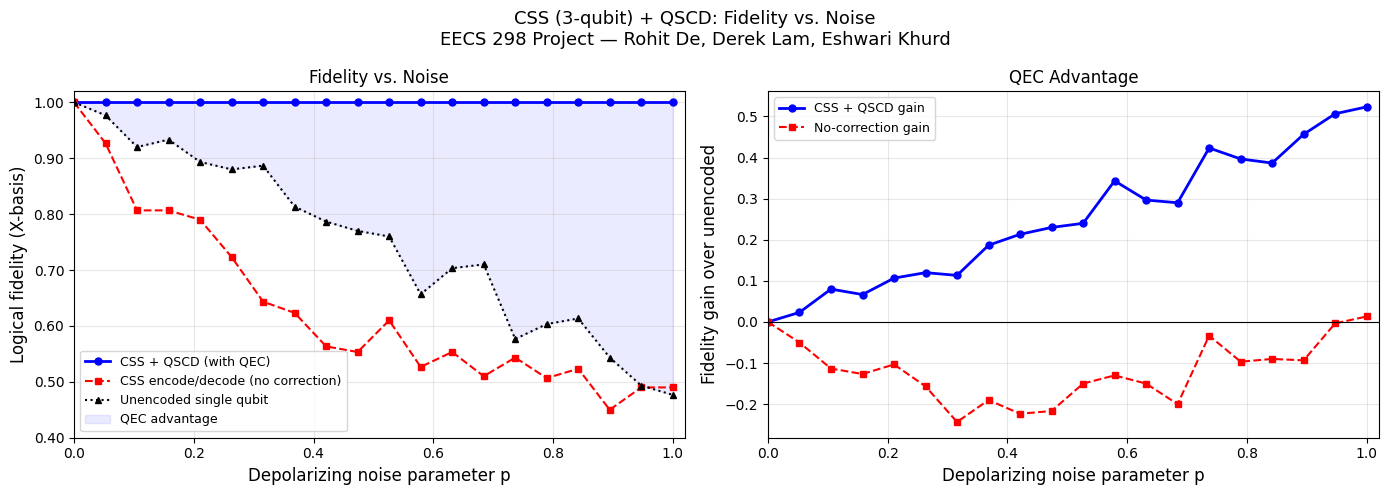

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 12 — Run everything
# ─────────────────────────────────────────────────────────────────────────────
if __name__ == '__main__':
    print('EECS 298 — CSS + QSCD  (two-pass density matrix)\n')

    inspect_circuits()

    p_values = np.linspace(0, 1, 20)
    print(f'\nRunning sweep over {len(p_values)} noise levels (300 shots each)...\n')

    fid_qec, fid_noqec, fid_raw = run_sweep(p_values=p_values, shots=300)

    plot_results(p_values, fid_qec, fid_noqec, fid_raw,
                 save_path='css_qscd_fidelity.png')


Plot saved to: css_qscd_fidelity.png


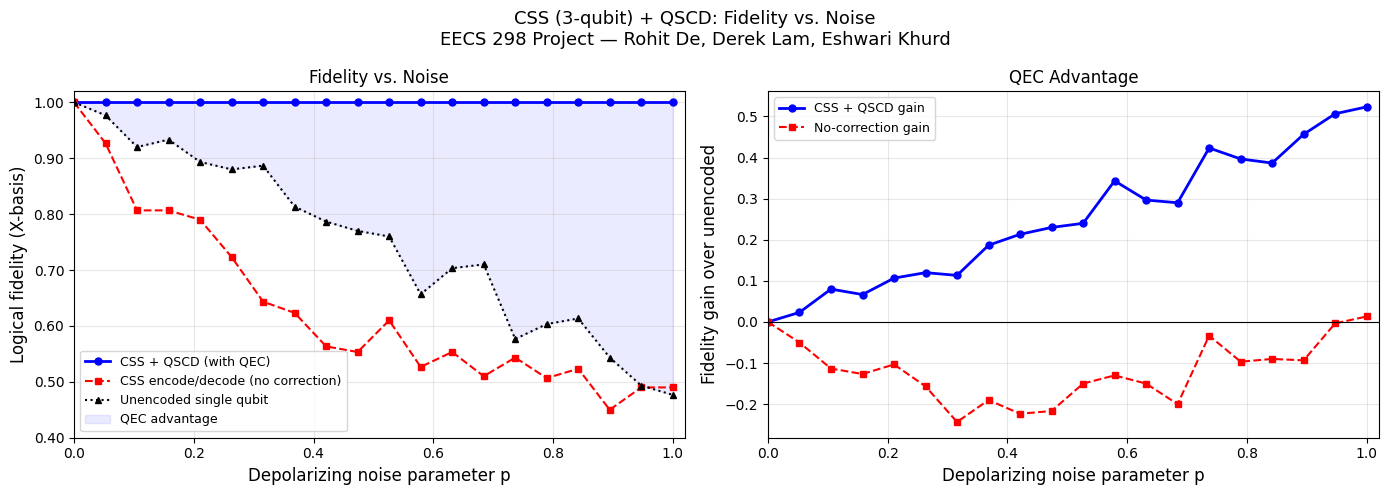

In [ ]:
plot_results(p_values, fid_qec, fid_noqec, fid_raw,
                 save_path='css_qscd_fidelity.png')

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Cell 13 — Single-error verification (all 9 Pauli errors)
# Confirms every stabilizer fires correctly before running the full sweep.
# ─────────────────────────────────────────────────────────────────────────────
def verify_single_error(error_type: str, qubit_index: int):
    """
    Inject one Pauli error (X / Z / Y) on one qubit (no other noise).
    Run the two-pass density matrix pipeline and return fidelity + syndrome.
    Uses the same Pass 1 / Pass 2 structure as estimate_fidelity_qec.
    """
    sim = AerSimulator(method='density_matrix')

    # ── Pass 1: encode → inject error → measure syndrome ──────────────
    data     = QuantumRegister(3, 'data')
    anc      = QuantumRegister(3, 'anc')
    syndrome = ClassicalRegister(3, 'syn')
    qc1      = QuantumCircuit(data, anc, syndrome)

    qc1.h(data[0])
    css_encode(qc1, data)

    # Inject error manually (no noise model — deterministic)
    if error_type == 'X': qc1.x(data[qubit_index])
    elif error_type == 'Z': qc1.z(data[qubit_index])
    elif error_type == 'Y': qc1.y(data[qubit_index])

    # Z-type stabilizers
    qc1.cx(data[0], anc[0]); qc1.cx(data[1], anc[0])   # Z₀Z₁
    qc1.cx(data[1], anc[1]); qc1.cx(data[2], anc[1])   # Z₁Z₂

    # X₀X₁X₂ stabilizer
    qc1.h(anc[2])
    qc1.cx(anc[2], data[0]); qc1.cx(anc[2], data[1]); qc1.cx(anc[2], data[2])
    qc1.h(anc[2])

    qc1.measure(anc[0], syndrome[0])
    qc1.measure(anc[1], syndrome[1])
    qc1.measure(anc[2], syndrome[2])
    qc1.save_density_matrix()

    # Run with NO noise model — only the manually injected error fires
    result1 = sim.run(transpile(qc1, sim), shots=1).result()

    syn_str        = list(result1.get_counts().keys())[0]
    x_corr, z_corr = decode_syndrome(syn_str)

    # ── Pass 2: load state, correct, decode, measure ───────────────────
    dm_full = DensityMatrix(result1.data()['density_matrix'])
    dm      = partial_trace(dm_full, [3, 4, 5])

    data2 = QuantumRegister(3, 'data')
    out2  = ClassicalRegister(1, 'out')
    qc2   = QuantumCircuit(data2, out2)
    qc2.set_density_matrix(dm)

    if x_corr is not None: qc2.x(data2[x_corr[1]])
    if z_corr is not None: qc2.z(data2[z_corr[1]])

    css_decode(qc2, data2)
    qc2.h(data2[0])              # rotate to X basis for |+⟩ fidelity
    qc2.measure(data2[0], out2[0])

    result2 = sim.run(transpile(qc2, sim), shots=1).result()
    recovered = list(result2.get_counts().keys())[0] == '0'

    # Human-readable syndrome: reverse the Qiskit LSB-first string
    syn_readable = syn_str[::-1]   # now s0 s1 sz left-to-right

    return recovered, syn_readable, x_corr, z_corr


# ── Run all 9 single-qubit Pauli errors ────────────────────────────────────
print(f'{"Error":<6} {"Qubit":<7} {"Syn(s0,s1,sz)":<15} '
      f'{"X fix":<16} {"Z fix":<16} {"Result"}')
print('-' * 72)

all_pass = True
for etype in ['X', 'Z', 'Y']:
    for q in [0, 1, 2]:
        ok, syn, xc, zc = verify_single_error(etype, q)
        status = '✓' if ok else '✗  ← PROBLEM'
        if not ok: all_pass = False
        print(f'{etype:<6} {q:<7} {syn:<15} {str(xc):<16} {str(zc):<16} {status}')
    print()

print('All single-qubit errors corrected:', '✓ YES' if all_pass else '✗ NO — check syndrome tables')

Error  Qubit   Syn(s0,s1,sz)   X fix            Z fix            Result
------------------------------------------------------------------------
X      0       100             ('X', 1)         None             ✓
X      1       110             ('X', 0)         None             ✓
X      2       010             ('X', 2)         None             ✓

Z      0       001             None             ('Z', 0)         ✓
Z      1       001             None             ('Z', 0)         ✓
Z      2       001             None             ('Z', 0)         ✓

Y      0       101             ('X', 1)         ('Z', 0)         ✓
Y      1       111             ('X', 0)         ('Z', 0)         ✓
Y      2       011             ('X', 2)         ('Z', 0)         ✓

All single-qubit errors corrected: ✓ YES
